In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option("display.max_columns", None)

# Load Dataset
df = pd.read_csv("../dataset/Obfuscated-MalMem2022.csv")

print("✅ Dataset Loaded Successfully")

✅ Dataset Loaded Successfully


In [2]:
df.head()

,Category,pslist.nproc,pslist.nppid,pslist.avg_threads,pslist.nprocs64bit,pslist.avg_handlers,dlllist.ndlls,dlllist.avg_dlls_per_proc,handles.nhandles,handles.avg_handles_per_proc,handles.nport,handles.nfile,handles.nevent,handles.ndesktop,handles.nkey,handles.nthread,handles.ndirectory,handles.nsemaphore,handles.ntimer,handles.nsection,handles.nmutant,ldrmodules.not_in_load,ldrmodules.not_in_init,ldrmodules.not_in_mem,ldrmodules.not_in_load_avg,ldrmodules.not_in_init_avg,ldrmodules.not_in_mem_avg,malfind.ninjections,malfind.commitCharge,malfind.protection,malfind.uniqueInjections,psxview.not_in_pslist,psxview.not_in_eprocess_pool,psxview.not_in_ethread_pool,psxview.not_in_pspcid_list,psxview.not_in_csrss_handles,psxview.not_in_session,psxview.not_in_deskthrd,psxview.not_in_pslist_false_avg,psxview.not_in_eprocess_pool_false_avg,psxview.not_in_ethread_pool_false_avg,psxview.not_in_pspcid_list_false_avg,psxview.not_in_csrss_handles_false_avg,psxview.not_in_session_false_avg,psxview.not_in_deskthrd_false_avg,modules.nmodules,svcscan.nservices,svcscan.kernel_drivers,svcscan.fs_drivers,svcscan.process_services,svcscan.shared_process_services,svcscan.interactive_process_services,svcscan.nactive,callbacks.ncallbacks,callbacks.nanonymous,callbacks.ngeneric,Class
0,Benign,45,17,10.555555,0,202.84445,1694,38.500000,9129,212.30232,0,670,3161,46,716,887,104,671,125,184,257,53,95,53,0.030372,0.054441,0.030372,5,21,30,1.250000,2,0,3,2,7,4,9,0.042553,0.0,0.063830,0.042553,0.148936,0.085106,0.191489,138,389,221,26,24,116,0,121,87,0,8,Benign
1,Benign,47,19,11.531915,0,242.23404,2074,44.127660,11385,242.23404,0,840,3761,51,1011,1030,117,766,148,337,394,77,123,77,0.036167,0.057774,0.036167,12,77,72,1.714286,0,0,0,0,4,2,6,0.000000,0.0,0.000000,0.000000,0.085106,0.042553,0.127660,138,392,222,26,24,118,0,122,87,0,8,Benign
2,Benign,40,14,14.725000,0,288.22500,1932,48.300000,11529,288.22500,0,1050,3996,45,784,1241,100,645,138,369,338,51,89,51,0.026114,0.045571,0.026114,5,6,30,1.250000,0,0,0,0,4,2,5,0.000000,0.0,0.000000,0.000000,0.100000,0.050000,0.125000,137,395,222,26,27,118,0,120,88,0,8,Benign
3,Benign,32,13,13.500000,0,264.28125,1445,45.156250,8457,264.28125,0,630,2961,36,654,792,83,567,127,186,242,31,62,31,0.021483,0.042966,0.021483,2,2,12,1.000000,0,0,0,0,4,2,6,0.000000,0.0,0.000000,0.000000,0.125000,0.062500,0.187500,138,395,222,26,27,118,0,120,88,0,8,Benign
4,Benign,42,16,11.452381,0,281.33334,2067,49.214287,11816,281.33334,0,908,3834,45,1252,942,103,825,135,375,429,102,143,102,0.047820,0.067042,0.047820,12,77,72,2.000000,4,0,4,4,8,6,10,0.086957,0.0,0.086957,0.086957,0.173913,0.130435,0.217391,138,392,222,26,24,118,0,124,87,0,8,Benign


In [3]:
df.shape

(58058, 57)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58058 entries, 0 to 58057
Data columns (total 57 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Category                                58058 non-null  object 
 1   pslist.nproc                            58058 non-null  int64  
 2   pslist.nppid                            58058 non-null  int64  
 3   pslist.avg_threads                      58058 non-null  float64
 4   pslist.nprocs64bit                      58058 non-null  int64  
 5   pslist.avg_handlers                     58058 non-null  float64
 6   dlllist.ndlls                           58058 non-null  int64  
 7   dlllist.avg_dlls_per_proc               58058 non-null  float64
 8   handles.nhandles                        58058 non-null  int64  
 9   handles.avg_handles_per_proc            58058 non-null  float64
 10  handles.nport                           58058 non-null  in

In [5]:
df.columns

Index(['Category', 'pslist.nproc', 'pslist.nppid', 'pslist.avg_threads',
       'pslist.nprocs64bit', 'pslist.avg_handlers', 'dlllist.ndlls',
       'dlllist.avg_dlls_per_proc', 'handles.nhandles',
       'handles.avg_handles_per_proc', 'handles.nport', 'handles.nfile',
       'handles.nevent', 'handles.ndesktop', 'handles.nkey', 'handles.nthread',
       'handles.ndirectory', 'handles.nsemaphore', 'handles.ntimer',
       'handles.nsection', 'handles.nmutant', 'ldrmodules.not_in_load',
       'ldrmodules.not_in_init', 'ldrmodules.not_in_mem',
       'ldrmodules.not_in_load_avg', 'ldrmodules.not_in_init_avg',
       'ldrmodules.not_in_mem_avg', 'malfind.ninjections',
       'malfind.commitCharge', 'malfind.protection',
       'malfind.uniqueInjections', 'psxview.not_in_pslist',
       'psxview.not_in_eprocess_pool', 'psxview.not_in_ethread_pool',
       'psxview.not_in_pspcid_list', 'psxview.not_in_csrss_handles',
       'psxview.not_in_session', 'psxview.not_in_deskthrd',
       'psxv

In [6]:
df.head()

,Category,pslist.nproc,pslist.nppid,pslist.avg_threads,pslist.nprocs64bit,pslist.avg_handlers,dlllist.ndlls,dlllist.avg_dlls_per_proc,handles.nhandles,handles.avg_handles_per_proc,handles.nport,handles.nfile,handles.nevent,handles.ndesktop,handles.nkey,handles.nthread,handles.ndirectory,handles.nsemaphore,handles.ntimer,handles.nsection,handles.nmutant,ldrmodules.not_in_load,ldrmodules.not_in_init,ldrmodules.not_in_mem,ldrmodules.not_in_load_avg,ldrmodules.not_in_init_avg,ldrmodules.not_in_mem_avg,malfind.ninjections,malfind.commitCharge,malfind.protection,malfind.uniqueInjections,psxview.not_in_pslist,psxview.not_in_eprocess_pool,psxview.not_in_ethread_pool,psxview.not_in_pspcid_list,psxview.not_in_csrss_handles,psxview.not_in_session,psxview.not_in_deskthrd,psxview.not_in_pslist_false_avg,psxview.not_in_eprocess_pool_false_avg,psxview.not_in_ethread_pool_false_avg,psxview.not_in_pspcid_list_false_avg,psxview.not_in_csrss_handles_false_avg,psxview.not_in_session_false_avg,psxview.not_in_deskthrd_false_avg,modules.nmodules,svcscan.nservices,svcscan.kernel_drivers,svcscan.fs_drivers,svcscan.process_services,svcscan.shared_process_services,svcscan.interactive_process_services,svcscan.nactive,callbacks.ncallbacks,callbacks.nanonymous,callbacks.ngeneric,Class
0,Benign,45,17,10.555555,0,202.84445,1694,38.500000,9129,212.30232,0,670,3161,46,716,887,104,671,125,184,257,53,95,53,0.030372,0.054441,0.030372,5,21,30,1.250000,2,0,3,2,7,4,9,0.042553,0.0,0.063830,0.042553,0.148936,0.085106,0.191489,138,389,221,26,24,116,0,121,87,0,8,Benign
1,Benign,47,19,11.531915,0,242.23404,2074,44.127660,11385,242.23404,0,840,3761,51,1011,1030,117,766,148,337,394,77,123,77,0.036167,0.057774,0.036167,12,77,72,1.714286,0,0,0,0,4,2,6,0.000000,0.0,0.000000,0.000000,0.085106,0.042553,0.127660,138,392,222,26,24,118,0,122,87,0,8,Benign
2,Benign,40,14,14.725000,0,288.22500,1932,48.300000,11529,288.22500,0,1050,3996,45,784,1241,100,645,138,369,338,51,89,51,0.026114,0.045571,0.026114,5,6,30,1.250000,0,0,0,0,4,2,5,0.000000,0.0,0.000000,0.000000,0.100000,0.050000,0.125000,137,395,222,26,27,118,0,120,88,0,8,Benign
3,Benign,32,13,13.500000,0,264.28125,1445,45.156250,8457,264.28125,0,630,2961,36,654,792,83,567,127,186,242,31,62,31,0.021483,0.042966,0.021483,2,2,12,1.000000,0,0,0,0,4,2,6,0.000000,0.0,0.000000,0.000000,0.125000,0.062500,0.187500,138,395,222,26,27,118,0,120,88,0,8,Benign
4,Benign,42,16,11.452381,0,281.33334,2067,49.214287,11816,281.33334,0,908,3834,45,1252,942,103,825,135,375,429,102,143,102,0.047820,0.067042,0.047820,12,77,72,2.000000,4,0,4,4,8,6,10,0.086957,0.0,0.086957,0.086957,0.173913,0.130435,0.217391,138,392,222,26,24,118,0,124,87,0,8,Benign


In [7]:
df.describe()

,pslist.nproc,pslist.nppid,pslist.avg_threads,pslist.nprocs64bit,pslist.avg_handlers,dlllist.ndlls,dlllist.avg_dlls_per_proc,handles.nhandles,handles.avg_handles_per_proc,handles.nport,handles.nfile,handles.nevent,handles.ndesktop,handles.nkey,handles.nthread,handles.ndirectory,handles.nsemaphore,handles.ntimer,handles.nsection,handles.nmutant,ldrmodules.not_in_load,ldrmodules.not_in_init,ldrmodules.not_in_mem,ldrmodules.not_in_load_avg,ldrmodules.not_in_init_avg,ldrmodules.not_in_mem_avg,malfind.ninjections,malfind.commitCharge,malfind.protection,malfind.uniqueInjections,psxview.not_in_pslist,psxview.not_in_eprocess_pool,psxview.not_in_ethread_pool,psxview.not_in_pspcid_list,psxview.not_in_csrss_handles,psxview.not_in_session,psxview.not_in_deskthrd,psxview.not_in_pslist_false_avg,psxview.not_in_eprocess_pool_false_avg,psxview.not_in_ethread_pool_false_avg,psxview.not_in_pspcid_list_false_avg,psxview.not_in_csrss_handles_false_avg,psxview.not_in_session_false_avg,psxview.not_in_deskthrd_false_avg,modules.nmodules,svcscan.nservices,svcscan.kernel_drivers,svcscan.fs_drivers,svcscan.process_services,svcscan.shared_process_services,svcscan.interactive_process_services,svcscan.nactive,callbacks.ncallbacks,callbacks.nanonymous,callbacks.ngeneric
count,58058.000000,58058.000000,58058.000000,58058.0,58058.000000,58058.000000,58058.000000,5.805800e+04,58058.000000,58058.0,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.000000,58058.00000,58058.000000,58058.0,58058.000000,58058.000000,58058.000000,58058.000000
mean,41.407455,14.709549,11.350468,0.0,247.800239,1812.943315,43.744795,1.027403e+04,249.851246,0.0,901.054101,3577.822815,44.549158,775.173602,930.099194,102.432860,683.962537,130.422629,291.010955,313.083279,60.939664,100.066227,60.941937,0.033195,0.055230,0.033196,7.040597,977.254866,42.466396,1.739058,1.873833,0.002101,2.269610,1.877485,6.272710,3.873592,8.252764,0.040933,0.000080,0.047660,0.041020,0.141674,0.087893,0.187580,137.961848,391.366788,221.410038,25.996211,25.07136,116.887371,0.0,122.011299,86.912915,0.000861,7.999879
std,5.778080,2.661240,1.587708,0.0,112.288874,329.860993,5.738302,4.884754e+03,146.614680,0.0,3448.131310,805.505371,5.163827,150.518394,237.885420,9.783286,94.434915,14.956705,144.428820,73.199683,18.779518,21.460167,18.778017,0.009288,0.010143,0.009291,15.444035,6067.240061,92.656906,2.751563,2.999529,0.045793,4.621571,3.021410,4.622209,2.999536,4.737954,0.057566,0.001275,0.066821,0.058225,0.061352,0.055037,0.061466,0.197409,4.538973,1.999357,0.171579,1.53100,1.551258,0.0,2.819536,3.115413,0.029334,0.010980
min,21.000000,8.000000,1.650000,0.0,34.962500,670.000000,7.333334,3.514000e+03,71.139244,0.0,266.000000,966.000000,22.000000,284.000000,388.000000,57.000000,296.000000,69.000000,50.000000,118.000000,6.000000,16.000000,6.000000,0.016176,0.040526,0.016176,1.000000,1.000000,6.000000,1.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.025806,0.008333,0.043750,126.000000,94.000000,55.000000,6.000000,7.00000,26.000000,0.0,30.000000,50.000000,0.000000,7.000000
25%,40.000000,12.000000,9.973684,0.0,208.775000,1556.000000,38.850000,8.402000e+03,209.743740,0.0,646.000000,2923.000000,43.000000,675.000000,709.000000,99.000000,614.000000,120.000000,177.000000,259.000000,46.000000,85.000000,46.000000,0.028855,0.052396,0.028858,3.000000,3.000000,18.000000,1.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.100000,0.048780,0.146341,138.000000,389.000000,221.000000,26.0

In [8]:
df.isnull().sum()

Category                                  0
pslist.nproc                              0
pslist.nppid                              0
pslist.avg_threads                        0
pslist.nprocs64bit                        0
pslist.avg_handlers                       0
dlllist.ndlls                             0
dlllist.avg_dlls_per_proc                 0
handles.nhandles                          0
handles.avg_handles_per_proc              0
handles.nport                             0
handles.nfile                             0
handles.nevent                            0
handles.ndesktop                          0
handles.nkey                              0
handles.nthread                           0
handles.ndirectory                        0
handles.nsemaphore                        0
handles.ntimer                            0
handles.nsection                          0
handles.nmutant                           0
ldrmodules.not_in_load                    0
ldrmodules.not_in_init          

In [9]:
df.dtypes

Category                                   object
pslist.nproc                                int64
pslist.nppid                                int64
pslist.avg_threads                        float64
pslist.nprocs64bit                          int64
pslist.avg_handlers                       float64
dlllist.ndlls                               int64
dlllist.avg_dlls_per_proc                 float64
handles.nhandles                            int64
handles.avg_handles_per_proc              float64
handles.nport                               int64
handles.nfile                               int64
handles.nevent                              int64
handles.ndesktop                            int64
handles.nkey                                int64
handles.nthread                             int64
handles.ndirectory                          int64
handles.nsemaphore                          int64
handles.ntimer                              int64
handles.nsection                            int64


In [10]:
df["Category"].value_counts()

Category
Benign                                                                                   29227
Trojan-Zeus-0e410a79d87fecfd37f7831e4682ada7a2d480f0759a71fa3893a5500faf4070-5.raw           2
Trojan-Zeus-0e410a79d87fecfd37f7831e4682ada7a2d480f0759a71fa3893a5500faf4070-6.raw           2
Trojan-Zeus-0e410a79d87fecfd37f7831e4682ada7a2d480f0759a71fa3893a5500faf4070-7.raw           2
Trojan-Zeus-0e410a79d87fecfd37f7831e4682ada7a2d480f0759a71fa3893a5500faf4070-8.raw           2
                                                                                         ...  
Ransomware-Ako-00a2c6bab1e53f679cdd4fdc772cd291928c109b9b747652639a1700d844f719-6.raw        1
Ransomware-Ako-00a2c6bab1e53f679cdd4fdc772cd291928c109b9b747652639a1700d844f719-5.raw        1
Ransomware-Ako-00a2c6bab1e53f679cdd4fdc772cd291928c109b9b747652639a1700d844f719-4.raw        1
Ransomware-Ako-00a2c6bab1e53f679cdd4fdc772cd291928c109b9b747652639a1700d844f719-3.raw        1
Ransomware-Ako-00a2c6bab1e53f679cdd4fdc77

In [11]:
df["Class"].value_counts()

Class
Benign     29227
Malware    28831
Name: count, dtype: int64

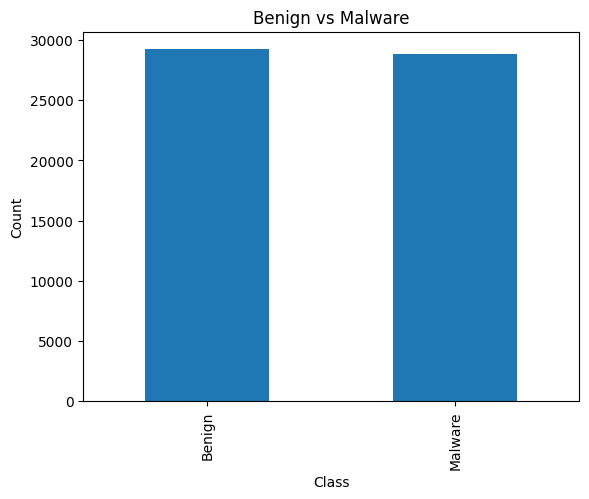

In [12]:
import matplotlib.pyplot as plt

df["Class"].value_counts().plot(kind="bar")

plt.title("Benign vs Malware")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

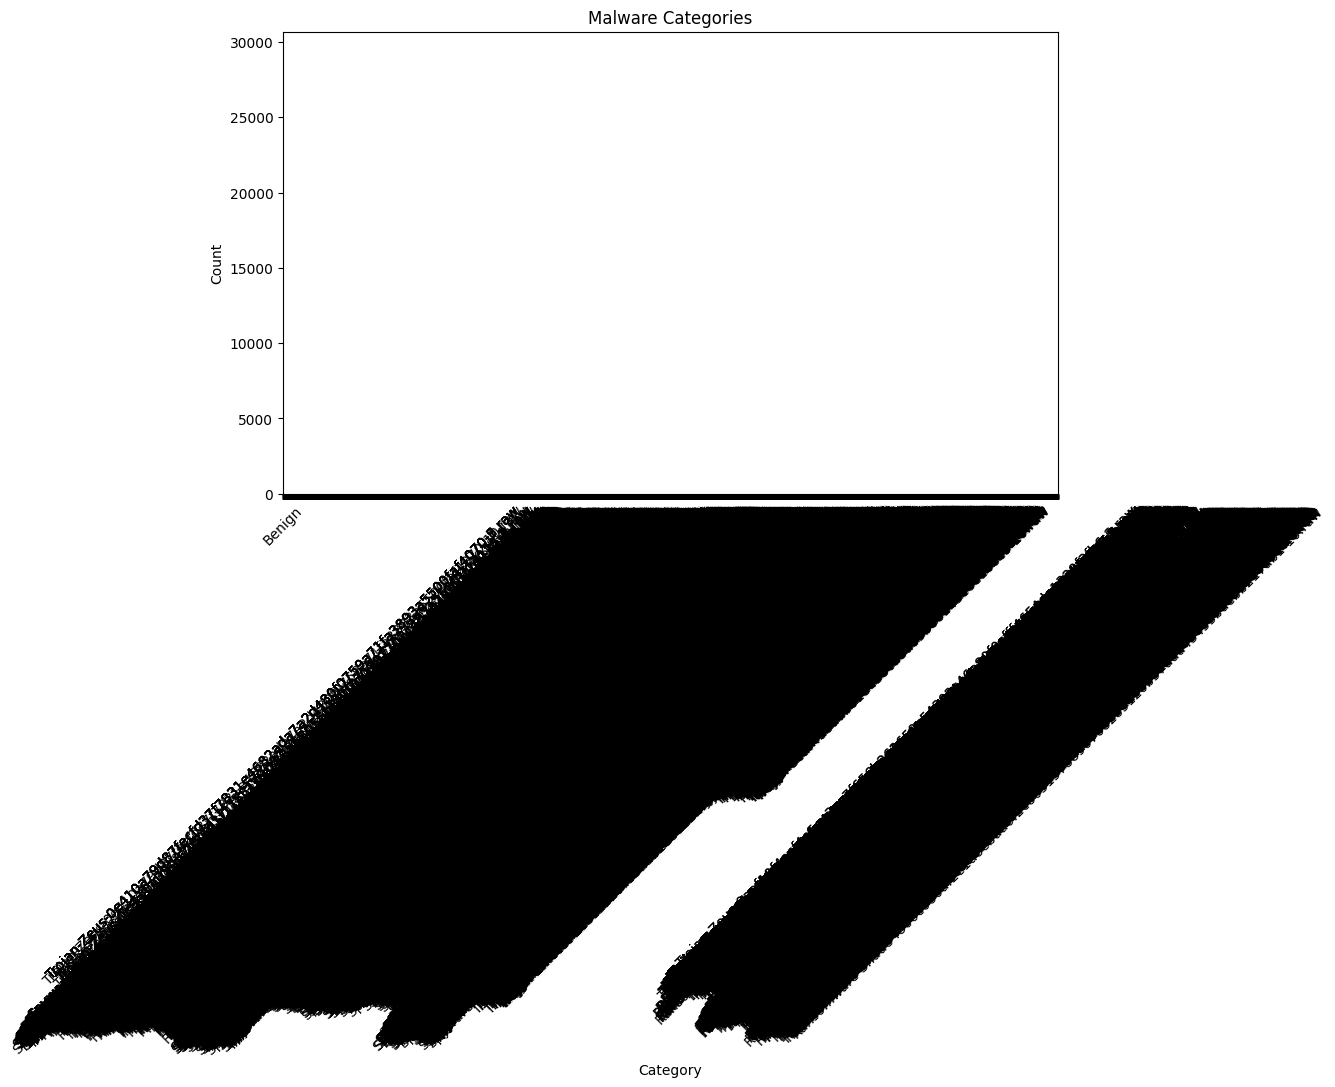

In [13]:
plt.figure(figsize=(10,6))

df["Category"].value_counts().plot(kind="bar")

plt.title("Malware Categories")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45)

plt.show()

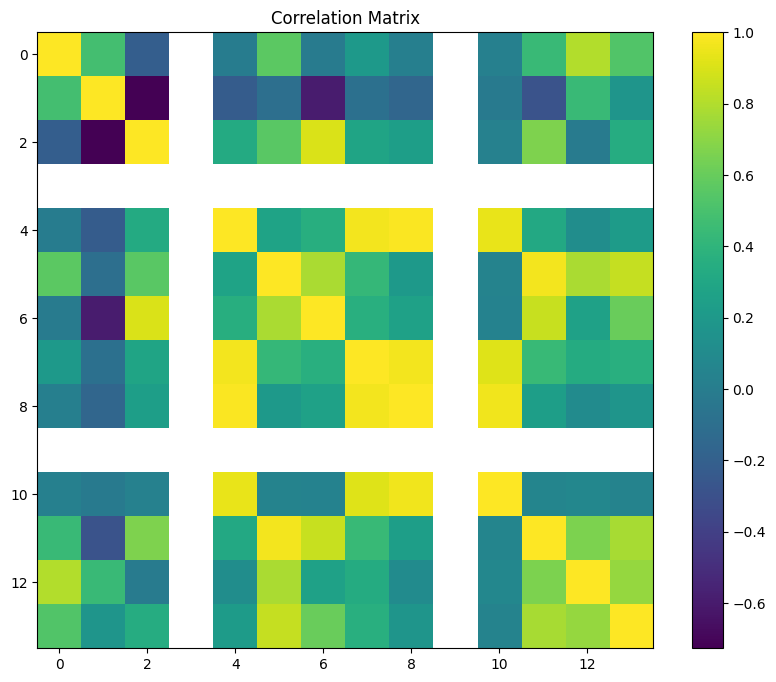

In [14]:
import matplotlib.pyplot as plt

corr = df.iloc[:,1:15].corr()

plt.figure(figsize=(10,8))
plt.imshow(corr)

plt.colorbar()

plt.title("Correlation Matrix")

plt.show()

In [15]:
df.to_csv("../dataset/clean_dataset.csv", index=False)

In [16]:
df["Class"].unique()

array(['Benign', 'Malware'], dtype=object)

In [17]:
df["Class"].unique()

array(['Benign', 'Malware'], dtype=object)

In [18]:
df["Class"].unique()

array(['Benign', 'Malware'], dtype=object)

In [19]:
df["Class"].value_counts()

Class
Benign     29227
Malware    28831
Name: count, dtype: int64

In [20]:
X = df.drop("Class", axis=1)
y = df["Class"]

print(X.shape)
print(y.shape)

(58058, 56)
(58058,)


In [21]:
X.dtypes

Category                                   object
pslist.nproc                                int64
pslist.nppid                                int64
pslist.avg_threads                        float64
pslist.nprocs64bit                          int64
pslist.avg_handlers                       float64
dlllist.ndlls                               int64
dlllist.avg_dlls_per_proc                 float64
handles.nhandles                            int64
handles.avg_handles_per_proc              float64
handles.nport                               int64
handles.nfile                               int64
handles.nevent                              int64
handles.ndesktop                            int64
handles.nkey                                int64
handles.nthread                             int64
handles.ndirectory                          int64
handles.nsemaphore                          int64
handles.ntimer                              int64
handles.nsection                            int64


In [22]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

X["Category"] = le.fit_transform(X["Category"])

In [23]:
X.dtypes

Category                                    int64
pslist.nproc                                int64
pslist.nppid                                int64
pslist.avg_threads                        float64
pslist.nprocs64bit                          int64
pslist.avg_handlers                       float64
dlllist.ndlls                               int64
dlllist.avg_dlls_per_proc                 float64
handles.nhandles                            int64
handles.avg_handles_per_proc              float64
handles.nport                               int64
handles.nfile                               int64
handles.nevent                              int64
handles.ndesktop                            int64
handles.nkey                                int64
handles.nthread                             int64
handles.ndirectory                          int64
handles.nsemaphore                          int64
handles.ntimer                              int64
handles.nsection                            int64


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(46446, 56)
(11612, 56)


In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [26]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [27]:
y_pred = model.predict(X_test)

In [28]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9999138821908371


In [29]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred))

print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5783
     Malware       1.00      1.00      1.00      5829

    accuracy                           1.00     11612
   macro avg       1.00      1.00      1.00     11612
weighted avg       1.00      1.00      1.00     11612

[[5782    1]
 [   0 5829]]


In [30]:
df["Class"].unique()

array(['Benign', 'Malware'], dtype=object)

In [31]:
df["Class"].value_counts()

Class
Benign     29227
Malware    28831
Name: count, dtype: int64

In [32]:
# Check missing values
df.isnull().sum()

Category                                  0
pslist.nproc                              0
pslist.nppid                              0
pslist.avg_threads                        0
pslist.nprocs64bit                        0
pslist.avg_handlers                       0
dlllist.ndlls                             0
dlllist.avg_dlls_per_proc                 0
handles.nhandles                          0
handles.avg_handles_per_proc              0
handles.nport                             0
handles.nfile                             0
handles.nevent                            0
handles.ndesktop                          0
handles.nkey                              0
handles.nthread                           0
handles.ndirectory                        0
handles.nsemaphore                        0
handles.ntimer                            0
handles.nsection                          0
handles.nmutant                           0
ldrmodules.not_in_load                    0
ldrmodules.not_in_init          

In [33]:
# Remove duplicates
df = df.drop_duplicates()

print(df.shape)

(58058, 57)


In [34]:
X = df.drop(["Category","Class"], axis=1)

y = df["Class"]

In [35]:
print(X.shape)
print(y.shape)

(58058, 55)
(58058,)


In [36]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y = le.fit_transform(y)

print(y[:10])

[0 0 0 0 0 0 0 0 0 0]


In [37]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [38]:
print(X_train.shape)
print(X_test.shape)

(46446, 55)
(11612, 55)


In [39]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)

model.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [40]:
y_pred = model.predict(X_test)

In [41]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test,y_pred)

0.9999138821908371

In [42]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5783
           1       1.00      1.00      1.00      5829

    accuracy                           1.00     11612
   macro avg       1.00      1.00      1.00     11612
weighted avg       1.00      1.00      1.00     11612



In [43]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test,y_pred)

print(cm)

[[5782    1]
 [   0 5829]]


In [44]:
import joblib

joblib.dump(model, "../models/malware_detector.pkl")

print("✅ Model Saved Successfully")

✅ Model Saved Successfully


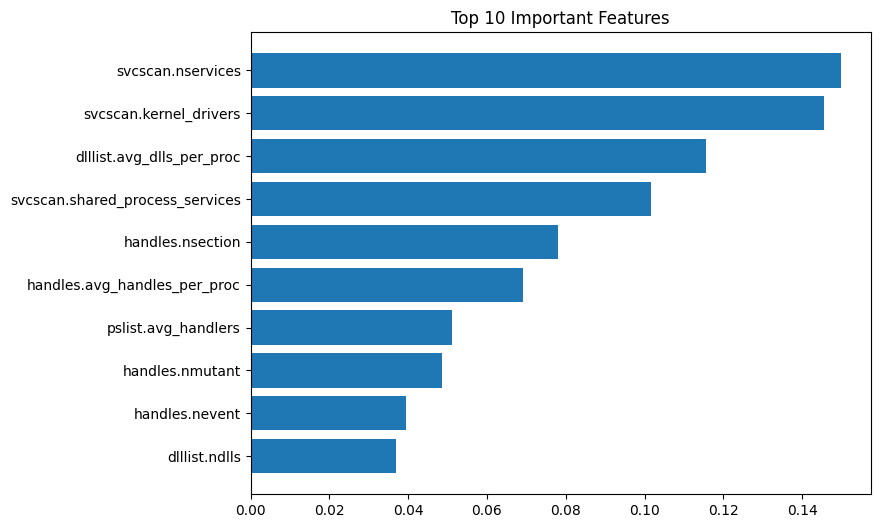

In [45]:
import matplotlib.pyplot as plt

importance = model.feature_importances_

features = X.columns

indices = importance.argsort()[-10:]

plt.figure(figsize=(8,6))
plt.barh(features[indices],importance[indices])
plt.title("Top 10 Important Features")
plt.show()